# NFL Draft Prediction

Can a player's physical profile and combine results predict whether he gets drafted?

This notebook walks through a complete, leak-free modelling workflow on a dataset of college players (draft years 2009–2019): data audit, exploratory analysis, feature engineering, model comparison with repeated cross-validation, diagnostics and final predictions.

**Key findings**

1. **Roughly 65% of players are drafted**, with large differences by position (kickers, punters and long snappers are rarely drafted).
2. **`Age` is missing almost exclusively for undrafted players** (44% of undrafted vs 0.4% of drafted). The "Age is missing" flag alone reaches 0.72 AUC, so it behaves like a proxy for the target rather than athletic ability. I therefore report results both with and without it.
3. With the flag the models reach **~0.84 AUC**; without it they reach **~0.76 AUC** using body measurements, combine results, position and age.
4. Engineered features add only small gains (≤0.005 AUC each, shown by ablation). The signal is dominated by age information and position, and when the age flag is available a regularised logistic regression is as good as gradient boosting.

**Contents:** 1 Setup · 2 Data · 3 Exploratory analysis · 4 Feature engineering · 5 Modelling and validation · 6 Diagnostics · 7 Feature importance · 8 Final predictions · 9 Conclusions

## 1. Setup

The notebook runs the same way on a local machine, in Jupyter/VS Code, or on Google Colab, with no hard-coded paths:

* It finds the project folder by searching the current working directory, its parent folders and its sub-folders for `src/features.py` (or use the `NFL_PROJECT_DIR` environment variable).
* It reads the data from `<project>/data/` (or the folder in `NFL_DATA_DIR`).
* Missing Python packages are installed automatically.

In [1]:
import os, sys, subprocess, importlib.util, warnings
from pathlib import Path

# Install any missing dependency (useful on Colab or a fresh environment)
_REQUIRED = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
             "seaborn": "seaborn", "lightgbm": "lightgbm", "xgboost": "xgboost", "catboost": "catboost"}
_missing = [pkg for mod, pkg in _REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

def find_project_root():
    """Locate the project folder (the one that contains src/features.py)."""
    candidates = []
    if os.environ.get("NFL_PROJECT_DIR"):
        candidates.append(Path(os.environ["NFL_PROJECT_DIR"]).expanduser())
    here = Path.cwd().resolve()
    candidates += [here, *here.parents]
    for folder in candidates:
        if (folder / "src" / "features.py").exists():
            return folder
    # e.g. Colab: working directory is /content and the project was cloned inside it
    for child in sorted(p for p in here.iterdir() if p.is_dir()):
        if (child / "src" / "features.py").exists():
            return child
    raise FileNotFoundError(
        "Could not find the project folder (the one containing src/features.py). "
        "Start Jupyter from inside the project, run `%cd <project folder>` first, "
        "or set the NFL_PROJECT_DIR environment variable.")

ROOT = find_project_root()
DATA = Path(os.environ.get("NFL_DATA_DIR", ROOT / "data")).expanduser()
FIGS, OUT = ROOT / "figures", ROOT / "outputs"
FIGS.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

_missing_files = [f for f in ("train.csv", "test.csv") if not (DATA / f).exists()]
if _missing_files:
    raise FileNotFoundError(
        f"Missing {_missing_files} in the data folder. Place train.csv and test.csv in "
        "<project>/data/ (see data/README.md) or point NFL_DATA_DIR at the folder that contains them.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

sys.path.insert(0, str(ROOT / "src"))
from features import FeatureBuilder, COMBINE_TESTS

warnings.filterwarnings("ignore")
SEED = 42

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C_YES, C_NO = "#2a7f62", "#c8553d"   # drafted / not drafted

def save(name):
    plt.savefig(FIGS / f"{name}.png")

print("Setup complete.")

Setup complete.


## 2. Data

Two tables are provided: `train.csv` (labelled, 2,781 players) and `test.csv` (696 players without the `Drafted` label, used only to generate final predictions). Because the test file has no labels, **all model evaluation below uses cross-validation on the training data.**

| Column | Description | Unit (inferred from value ranges) |
|---|---|---|
| `Year` | Year of the record | – |
| `Age` | Player age | years |
| `School` | College | – |
| `Height`, `Weight` | Body measurements | m, kg |
| `Sprint_40yd` | 40-yard dash | seconds (lower is better) |
| `Vertical_Jump`, `Broad_Jump` | Jump distances | cm |
| `Bench_Press_Reps` | Bench-press repetitions | count |
| `Agility_3cone`, `Shuttle` | Agility drills | seconds (lower is better) |
| `Player_Type`, `Position_Type`, `Position` | Role at three levels of detail | – |
| `Drafted` | Target: 1 = drafted, 0 = not drafted | – |

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
y = train["Drafted"].astype(int).to_numpy()
X = train.drop(columns="Drafted")

print(f"train: {train.shape}   test: {test.shape}")
print(f"duplicate rows  train: {train.drop(columns='Id').duplicated().sum()}  test: {test.drop(columns='Id').duplicated().sum()}")
print(f"drafted rate (train): {y.mean():.1%}")
train.describe().T.round(2)

train: (2781, 16)   test: (696, 15)
duplicate rows  train: 0  test: 0
drafted rate (train): 64.8%


,count,mean,std,min,25%,50%,75%,max
Id,2781.0,1390.00,802.95,0.00,695.00,1390.00,2085.00,2780.00
Year,2781.0,2013.84,3.08,2009.00,2011.00,2014.00,2017.00,2019.00
Age,2346.0,22.00,0.96,18.00,21.00,22.00,23.00,28.00
Height,2781.0,1.87,0.07,1.65,1.83,1.88,1.93,2.08
Weight,2781.0,109.50,20.31,67.59,92.99,104.78,124.28,162.39
Sprint_40yd,2636.0,4.76,0.30,4.22,4.53,4.68,4.95,6.00
Vertical_Jump,2227.0,83.51,10.71,44.45,76.20,83.82,91.44,114.30
Bench_Press_Reps,2060.0,20.24,6.41,2.00,16.00,20.00,24.00,45.00
Broad_Jump,2200.0,291.99,23.92,198.12,276.86,294.64,307.34,373.38
Agility_3cone,1811.0,7.23,0.41,6.28,6.93,7.13,7.49,9.04


The value ranges confirm the units (weights of 68–162 kg, 40-yard times of 4.2–6.0 s, vertical jumps of 44–114 cm). Next I check that train and test come from the same population, since a mismatch would make the CV estimate unreliable.

In [3]:
shift = pd.DataFrame({
    "train": train[["Age", "Height", "Weight"] + COMBINE_TESTS].mean(),
    "test": test[["Age", "Height", "Weight"] + COMBINE_TESTS].mean(),
})
shift["train_missing"] = train[shift.index].isna().mean()
shift["test_missing"] = test[shift.index].isna().mean()
print("Position mix – max absolute difference in share:",
      round((train.Position.value_counts(normalize=True)
             .sub(test.Position.value_counts(normalize=True), fill_value=0)).abs().max(), 3))
print("Schools in test not seen in train:", int((~test.School.isin(train.School)).sum()), "of", len(test))
shift.round(3)

Position mix – max absolute difference in share: 0.025
Schools in test not seen in train: 17 of 696


,train,test,train_missing,test_missing
Age,21.997,21.928,0.156,0.165
Height,1.874,1.875,0.000,0.000
Weight,109.502,110.723,0.000,0.000
Sprint_40yd,4.765,4.786,0.052,0.042
Vertical_Jump,83.506,82.934,0.199,0.205
Bench_Press_Reps,20.236,20.260,0.259,0.264
Broad_Jump,291.986,290.203,0.209,0.211
Agility_3cone,7.230,7.266,0.349,0.355
Shuttle,4.399,4.421,0.328,0.328


Train and test are very similar (means, missing-value rates and position mix), so cross-validation on the training set is a reasonable guide to performance on the unlabelled players.

## 3. Exploratory analysis

### 3.1 Who gets drafted?

In [ ]:
pos_stats = (train.groupby("Position")["Drafted"].agg(rate="mean", n="size")
             .sort_values("rate", ascending=False))
pos_stats = pos_stats[pos_stats.n >= 10]          # hide the 2-row 'DB' category

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 3]})
counts = train["Drafted"].value_counts().sort_index()
ax[0].bar(["Not drafted", "Drafted"], counts.values, color=[C_NO, C_YES])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 25, f"{v:,}\n({v/len(train):.0%})", ha="center")
ax[0].set_ylim(0, counts.max() * 1.18); ax[0].set_title("Target balance")

ax[1].bar(pos_stats.index, pos_stats.rate, color=C_YES)
ax[1].axhline(y.mean(), color="k", ls="--", lw=1, label=f"overall {y.mean():.0%}")
ax[1].set_ylim(0, 1); ax[1].set_ylabel("Share drafted"); ax[1].legend()
ax[1].set_title("Draft rate by position (positions with n ≥ 10)")
plt.tight_layout(); save("01_target_and_positions"); plt.show()

Kickers (K), punters (P) and long snappers (LS) are drafted far less often than everyone else; fullbacks (FB) are also low. The classes are moderately imbalanced (65/35), so AUC is a suitable metric and stratified splits are used throughout.

### 3.2 Physical profile and combine results

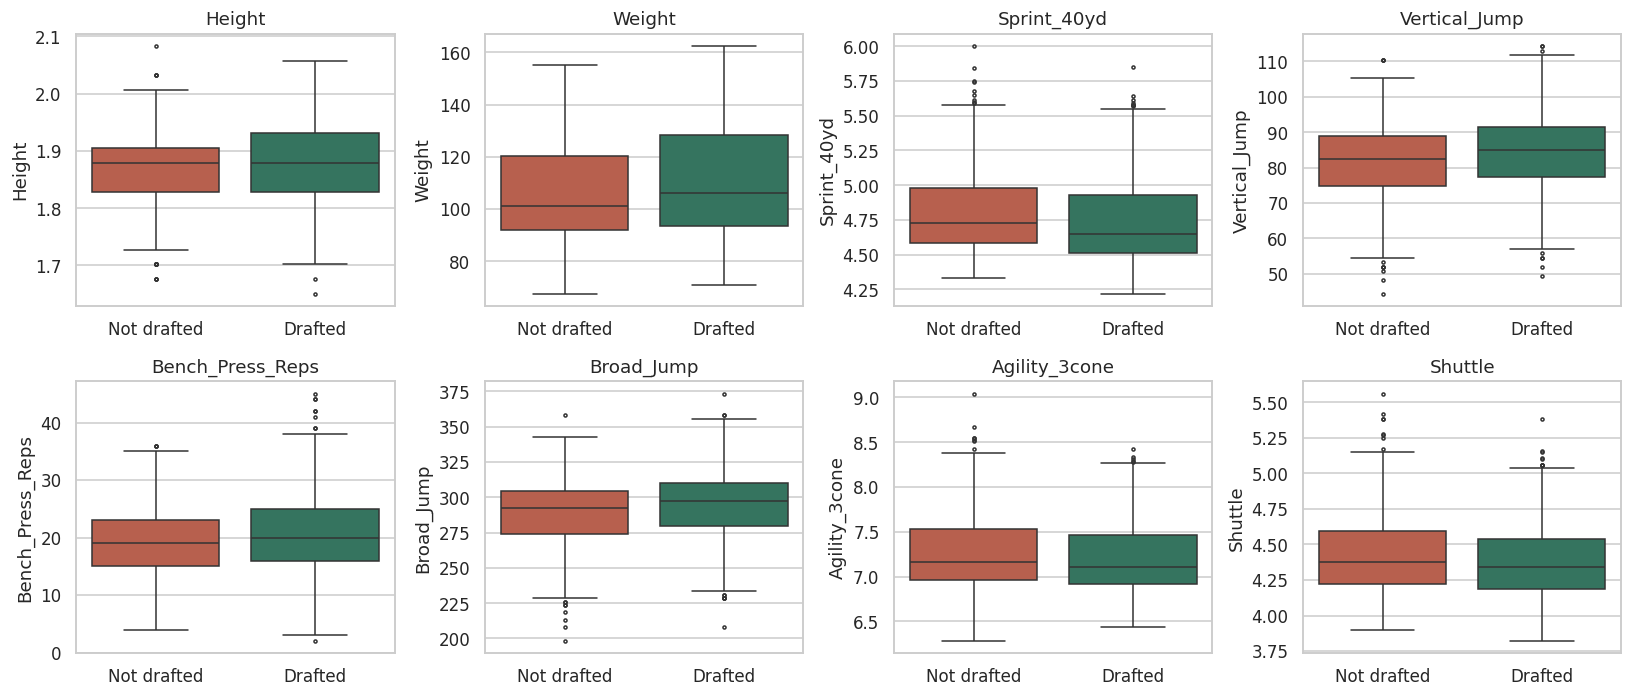

In [5]:
metrics = ["Height", "Weight"] + COMBINE_TESTS
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.ravel(), metrics):
    sns.boxplot(data=train, x="Drafted", y=col, hue="Drafted", palette={0: C_NO, 1: C_YES},
                legend=False, ax=ax, fliersize=2)
    ax.set_xlabel(""); ax.set_xticks([0, 1]); ax.set_xticklabels(["Not drafted", "Drafted"])
    ax.set_title(col)
plt.tight_layout(); save("02_metrics_by_outcome"); plt.show()

Raw differences between drafted and undrafted players are small, because positions differ so much physically (a lineman is slow and heavy by nature). This motivates **position-relative features** in section 4: a 4.9 s dash is excellent for a tackle and poor for a cornerback.

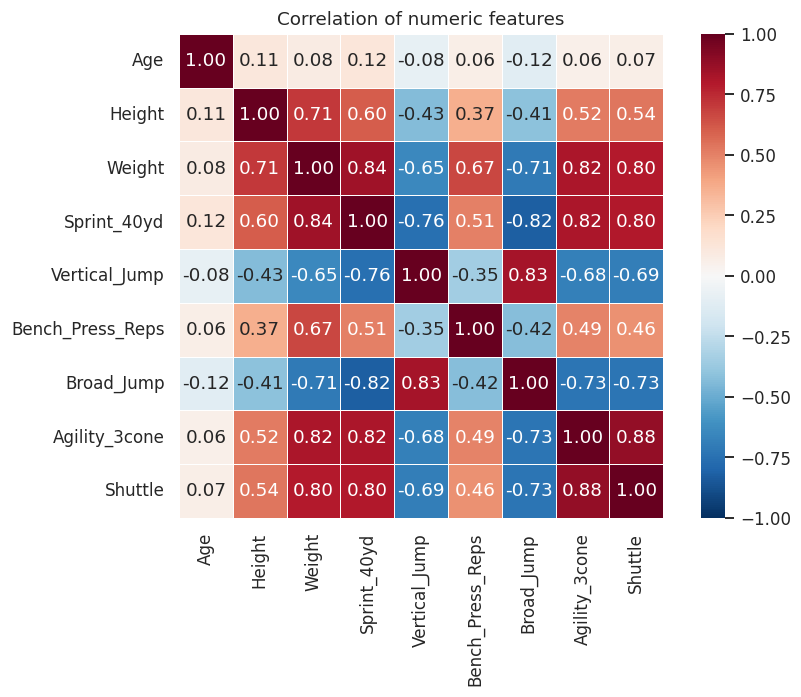

In [6]:
corr = train[["Age", "Height", "Weight"] + COMBINE_TESTS].corr()
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=.5, square=True)
plt.title("Correlation of numeric features"); plt.tight_layout(); save("03_correlation"); plt.show()

The two agility drills are strongly correlated (0.88), and `Sprint_40yd` is strongly *negatively* correlated with the jumps (-0.82) simply because it is a time (lower is better) while jumps are distances (higher is better). Weight correlates strongly with slow times, which again reflects position.

### 3.3 Missing data

,missing_rate,drafted_if_missing,drafted_if_observed
feature,,,
Age,0.156,0.018,0.765
Sprint_40yd,0.052,0.586,0.652
Vertical_Jump,0.199,0.585,0.664
Bench_Press_Reps,0.259,0.602,0.665
Broad_Jump,0.209,0.594,0.663
Agility_3cone,0.349,0.605,0.671
Shuttle,0.328,0.601,0.671


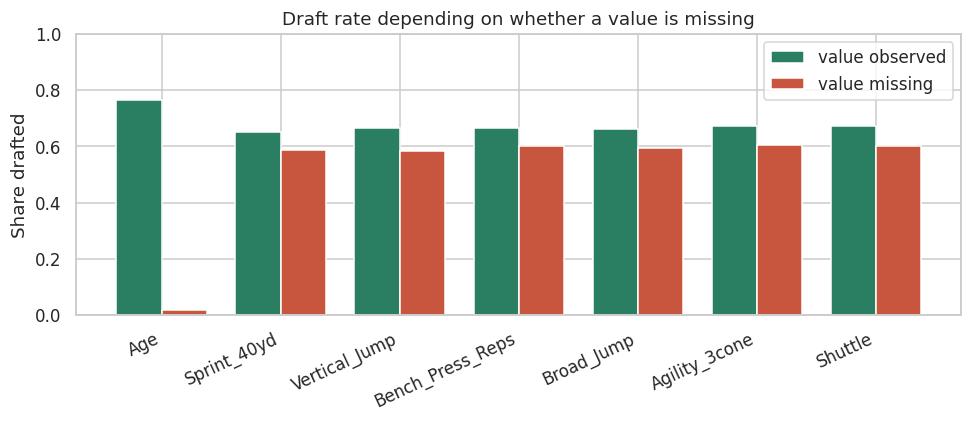

In [7]:
miss_cols = ["Age"] + COMBINE_TESTS
rows = []
for c in miss_cols:
    m = train[c].isna()
    rows.append({"feature": c, "missing_rate": m.mean(),
                 "drafted_if_missing": train.Drafted[m].mean(),
                 "drafted_if_observed": train.Drafted[~m].mean()})
miss = pd.DataFrame(rows).set_index("feature")
display(miss.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
w = 0.38; xs = np.arange(len(miss))
ax.bar(xs - w/2, miss.drafted_if_observed, w, label="value observed", color=C_YES)
ax.bar(xs + w/2, miss.drafted_if_missing, w, label="value missing", color=C_NO)
ax.set_xticks(xs); ax.set_xticklabels(miss.index, rotation=25, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("Share drafted"); ax.legend()
ax.set_title("Draft rate depending on whether a value is missing")
plt.tight_layout(); save("04_missingness_vs_target"); plt.show()

Missing combine results are only weakly informative (about 59–60% drafted when missing vs ~66% when present). **`Age` is a different story**: players with no recorded age are drafted just 2% of the time, versus 77% for those with an age.

### 3.4 The `Age` anomaly

Missing Age  | drafted players: 0.4%   undrafted players: 43.7%
AUC of the 'Age is missing' flag on its own: 0.716


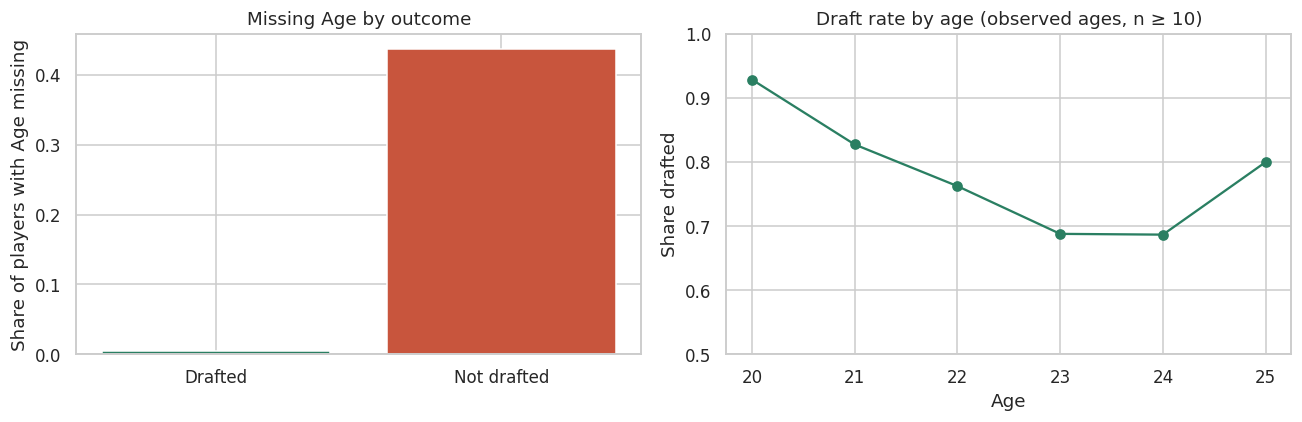

In [8]:
age_miss = train["Age"].isna()
print(f"Missing Age  | drafted players: {age_miss[y == 1].mean():.1%}   undrafted players: {age_miss[y == 0].mean():.1%}")
print(f"AUC of the 'Age is missing' flag on its own: {roc_auc_score(y, -age_miss.astype(int)):.3f}")

by_age = train.dropna(subset=["Age"]).groupby("Age")["Drafted"].agg(["mean", "size"])
by_age = by_age[by_age["size"] >= 10]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(["Drafted", "Not drafted"], [age_miss[y == 1].mean(), age_miss[y == 0].mean()], color=[C_YES, C_NO])
ax[0].set_ylabel("Share of players with Age missing"); ax[0].set_title("Missing Age by outcome")
ax[1].plot(by_age.index.astype(int), by_age["mean"], marker="o", color=C_YES)
ax[1].set_xlabel("Age"); ax[1].set_ylabel("Share drafted"); ax[1].set_ylim(0.5, 1)
ax[1].set_title("Draft rate by age (observed ages, n ≥ 10)")
plt.tight_layout(); save("05_age_anomaly"); plt.show()

Two separate things are happening:

* **Real signal in the age value.** Among players with a recorded age, younger players are drafted more often (93% at age 20, 69% at age 23).
* **A recording artifact in the missingness.** Age appears to be filled in for almost every drafted player but for only ~56% of undrafted players. This is information that would not exist *before* the draft, so a model that leans on `Age_Missing` is partly reading the answer from how the data was collected.

I won't silently drop this feature or silently keep it. Instead, every model is evaluated under three scenarios:

| Scenario | Age value | `Age_Missing` flag | Interpretation |
|---|---|---|---|
| **A. As provided** | yes | yes | Best score on this dataset, inflated by the artifact |
| **B. Age without flag** | yes (median-imputed) | no | Closest to a genuine pre-draft prediction |
| **C. No age** | no | no | Pure physical profile and position |

## 4. Feature engineering

All feature logic lives in [`src/features.py`](src/features.py) as a scikit-learn-style `FeatureBuilder`. Its key property is that **every statistic is learned from the training fold only** and then applied to the validation or test rows. This avoids two problems in a naive approach: computing position statistics separately on each dataset (so a test row is compared with other test rows) and target-encoding a row with its own label.

| Feature group | What it does |
|---|---|
| Imputation | Missing combine values and ages are filled with the **median of the player's position** (falling back to position type, then the global median, for rare positions) |
| Missingness | `Tests_Missing` (count of skipped drills) and, optionally, `Age_Missing` |
| Body | `Height`, `Weight`, `BMI` |
| Athletic metrics | `Speed_Score` (weight in lb × 200 / 40-time⁴, the standard NFL formula), `Burst` (vertical + broad jump in inches), `Agility_Sum`, `Bench_per_kg` |
| Position-relative | For each of the six drills, a z-score against the player's position (sign-flipped for timed drills so higher is always better) plus their mean, `Athletic_Composite` |
| School | Smoothed, out-of-fold draft rate of the player's school and school size |
| Position | One-hot encodings of `Player_Type`, `Position_Type` and `Position` |

In [9]:
fb = FeatureBuilder()
F = fb.fit_transform(X, y)
print(f"{F.shape[1]} features for {F.shape[0]} players")
print(", ".join(F.columns))

55 features for 2781 players
Tests_Missing, Age_Missing, Sprint_40yd, Vertical_Jump, Bench_Press_Reps, Broad_Jump, Agility_3cone, Shuttle, Age, Height, Weight, BMI, Speed_Score, Burst, Agility_Sum, Bench_per_kg, Sprint_40yd_pos_z, Vertical_Jump_pos_z, Bench_Press_Reps_pos_z, Broad_Jump_pos_z, Agility_3cone_pos_z, Shuttle_pos_z, Athletic_Composite, School_DraftRate, School_Size, Player_Type=defense, Player_Type=offense, Player_Type=special_teams, Position_Type=backs_receivers, Position_Type=defensive_back, Position_Type=defensive_lineman, Position_Type=kicking_specialist, Position_Type=line_backer, Position_Type=offensive_lineman, Position_Type=other_special, Position=C, Position=CB, Position=DB, Position=DE, Position=DT, Position=FB, Position=FS, Position=ILB, Position=K, Position=LS, Position=OG, Position=OLB, Position=OT, Position=P, Position=QB, Position=RB, Position=S, Position=SS, Position=TE, Position=WR


A quick univariate check shows what the position adjustment buys. Values are AUCs of the single feature for predicting `Drafted` (below 0.5 means *lower* values go with being drafted).

In [10]:
uni_cols = ["Sprint_40yd", "Sprint_40yd_pos_z", "Vertical_Jump", "Vertical_Jump_pos_z",
            "Bench_Press_Reps", "Bench_Press_Reps_pos_z", "Weight", "BMI",
            "Speed_Score", "Burst", "Athletic_Composite", "Tests_Missing", "Age"]
uni = pd.Series({c: roc_auc_score(y, F[c]) for c in uni_cols}, name="AUC").sort_values()
display(uni.round(3).to_frame())

,AUC
Sprint_40yd,0.425
Age,0.432
Tests_Missing,0.451
Weight,0.545
BMI,0.545
Vertical_Jump,0.558
Burst,0.562
Bench_Press_Reps_pos_z,0.566
Bench_Press_Reps,0.568
Vertical_Jump_pos_z,0.590


On their own, the position-relative 40-yard time and vertical jump are clearly more informative than the raw values (the raw 40-yard time has AUC 0.425, i.e. 0.575 once the direction is flipped, versus 0.671 after adjusting for position; bench press is about equal either way). `Speed_Score`, the position-adjusted 40-yard time and `Athletic_Composite` are the strongest single athletic features at roughly 0.67. Section 5.1 checks whether they still help once position is also in the model.

## 5. Modelling and validation

**Protocol**

* 5-fold stratified cross-validation repeated 3 times (15 validation folds), metric = ROC AUC.
* The `FeatureBuilder` is **re-fitted inside every fold**, so nothing from the validation rows leaks into imputation, position statistics or school encoding.
* Five model families with moderate, regularised settings (no heavy tuning, to avoid overfitting a small dataset), plus an **equal-weight average** of all five. Equal weights avoid hand-picking blend weights on the same data used to evaluate them.
* Each of the three age scenarios from section 3.4 is evaluated.

In [11]:
def make_models():
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=10,
                                                random_state=0, n_jobs=1),
        "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.02, num_leaves=8, max_depth=3,
                                   min_child_samples=30, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.7, reg_lambda=5, random_state=0,
                                   verbose=-1, n_jobs=1),
        "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.02, max_depth=3, min_child_weight=5,
                                 subsample=0.8, colsample_bytree=0.7, reg_lambda=5, random_state=0,
                                 n_jobs=1, eval_metric="auc"),
        "CatBoost": CatBoostClassifier(iterations=400, learning_rate=0.03, depth=4, l2_leaf_reg=5,
                                       random_seed=0, verbose=False, thread_count=1),
    }

SCENARIOS = {
    "A. As provided": {},
    "B. Age, no missing flag": {"use_age_missing_flag": False},
    "C. No age": {"use_age": False},
}
N_REPEATS = 3
splits = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS, random_state=SEED).split(X, y))

fold_scores, oof = [], {}
for scen, fb_kwargs in SCENARIOS.items():
    oof[scen] = {m: np.zeros((N_REPEATS, len(y))) for m in list(make_models()) + ["Blend (equal weights)"]}
    for k, (tr, va) in enumerate(splits):
        rep = k // 5
        fb = FeatureBuilder(**fb_kwargs)
        Xtr, Xva = fb.fit_transform(X.iloc[tr], y[tr]), fb.transform(X.iloc[va])
        preds = {}
        for name, model in make_models().items():
            model.fit(Xtr, y[tr])
            preds[name] = model.predict_proba(Xva)[:, 1]
        preds["Blend (equal weights)"] = np.mean(list(preds.values()), axis=0)
        for name, p in preds.items():
            oof[scen][name][rep, va] = p
            fold_scores.append({"scenario": scen, "model": name, "fold": k, "auc": roc_auc_score(y[va], p)})
    print("finished", scen)

scores = pd.DataFrame(fold_scores)
summary = (scores.groupby(["scenario", "model"])["auc"].agg(["mean", "std"]).round(4)
           .reset_index())
summary.to_csv(OUT / "cv_results.csv", index=False)
table = summary.pivot(index="model", columns="scenario", values="mean")
table = table.loc[list(make_models()) + ["Blend (equal weights)"]]
table

finished A. As provided


finished B. Age, no missing flag


finished C. No age


scenario,A. As provided,"B. Age, no missing flag",C. No age
model,,,
Logistic Regression,0.8384,0.7304,0.7244
Random Forest,0.8355,0.7480,0.7221
LightGBM,0.8384,0.7605,0.7276
XGBoost,0.8383,0.7609,0.7276
CatBoost,0.8396,0.7672,0.7323
Blend (equal weights),0.8415,0.7620,0.7318


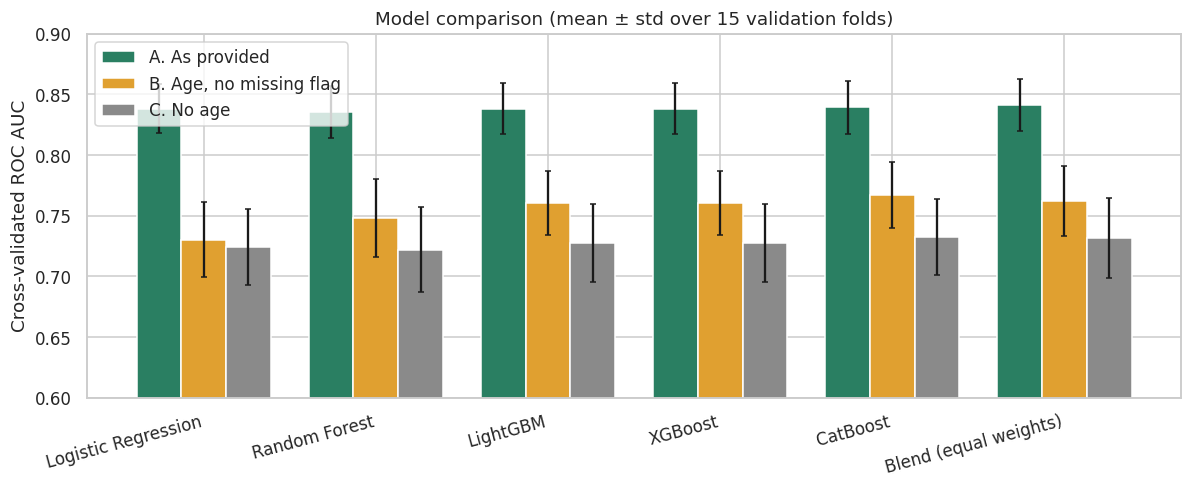

In [12]:
order = list(make_models()) + ["Blend (equal weights)"]
fig, ax = plt.subplots(figsize=(11, 4.6))
w = 0.26
for i, (scen, col) in enumerate(zip(SCENARIOS, ["#2a7f62", "#e0a030", "#8a8a8a"])):
    sub = summary[summary.scenario == scen].set_index("model").loc[order]
    ax.bar(np.arange(len(order)) + (i - 1) * w, sub["mean"], w, yerr=sub["std"], capsize=2,
           label=scen, color=col)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=15, ha="right")
ax.set_ylim(0.6, 0.9); ax.set_ylabel("Cross-validated ROC AUC"); ax.legend(loc="upper left")
ax.set_title("Model comparison (mean ± std over 15 validation folds)")
plt.tight_layout(); save("06_model_comparison"); plt.show()

**What the comparison says**

* **The age flag is worth ~0.08 AUC.** Scenario A scores ~0.84 for every model family, B ~0.73–0.77 and C ~0.72–0.73. Models are far more alike than the choice of scenario is.
* **Within a scenario, models are close.** In scenario A, logistic regression (0.838) matches the boosted trees (0.838–0.840), which is expected when most of the signal is one binary flag. The fold-to-fold standard deviation (~0.02) is larger than the gaps between models, so small differences should not be over-interpreted.
* **Where the athletic signal is subtler (scenarios B and C), boosting helps a little.** In B, the gradient boosters beat logistic regression by 0.03–0.04, so interactions between age, position and combine results carry some information.
* **Keeping the age value, even imputed, adds ~0.03** for the boosted models and the blend over dropping age altogether (B vs C); logistic regression gains almost nothing, so this effect is non-linear.
* The equal-weight blend is best in A and within about 0.005 AUC of the best single model in B and C. Because the best single model changes between scenarios, averaging is a safe choice for the final predictions.

### 5.1 Which feature groups matter?

To see what the engineering actually contributes, I remove one feature group at a time and re-score LightGBM on the same 15 folds (features are rebuilt in each fold as before).

In [13]:
GROUPS = {
    "none removed": lambda c: False,
    "position-relative (z-scores, composite)": lambda c: c.endswith("_pos_z") or c == "Athletic_Composite",
    "derived metrics (BMI, speed score, burst, ...)": lambda c: c in ["BMI", "Speed_Score", "Burst", "Agility_Sum", "Bench_per_kg"],
    "school features": lambda c: c.startswith("School_"),
    "Tests_Missing": lambda c: c == "Tests_Missing",
    "one-hot position columns": lambda c: "=" in c,
}
abl_rows = []
for scen in ["A. As provided", "B. Age, no missing flag"]:
    cache = []
    for tr, va in splits:
        fb = FeatureBuilder(**SCENARIOS[scen])
        cache.append((fb.fit_transform(X.iloc[tr], y[tr]), fb.transform(X.iloc[va]), tr, va))
    for name, rule in GROUPS.items():
        aucs = []
        for Ftr, Fva, tr, va in cache:
            drop = [c for c in Ftr.columns if rule(c)]
            m = make_models()["LightGBM"].fit(Ftr.drop(columns=drop), y[tr])
            aucs.append(roc_auc_score(y[va], m.predict_proba(Fva.drop(columns=drop))[:, 1]))
        abl_rows.append({"scenario": scen, "removed": name, "AUC": np.mean(aucs)})
abl = pd.DataFrame(abl_rows).pivot(index="removed", columns="scenario", values="AUC").loc[list(GROUPS)]
for col in abl.columns:
    abl[col + " (Δ)"] = abl[col] - abl.loc["none removed", col]
abl.round(4)

scenario,A. As provided,"B. Age, no missing flag",A. As provided (Δ),"B. Age, no missing flag (Δ)"
removed,,,,
none removed,0.8384,0.7605,0.0000,0.0000
"position-relative (z-scores, composite)",0.8379,0.7596,-0.0005,-0.0010
"derived metrics (BMI, speed score, burst, ...)",0.8335,0.7562,-0.0049,-0.0044
school features,0.8374,0.7585,-0.0011,-0.0021
Tests_Missing,0.8385,0.7603,0.0000,-0.0002
one-hot position columns,0.8348,0.7551,-0.0037,-0.0054


Removing any single group changes the AUC by at most about 0.005, well inside the ±0.02 fold-to-fold noise. The derived athletic metrics and the one-hot position columns matter most; the position-relative z-scores and `Tests_Missing` add essentially nothing *on top of* the other features, because a boosted tree given raw results plus position can learn "fast for his position" by itself. So the engineered features are best seen as useful, compact summaries (and strong on their own, as section 4 showed) rather than as a large source of extra accuracy. The real drivers are age information and position.

## 6. Diagnostics

Out-of-fold predictions (averaged over the three repeats) are used for the plots below, so every prediction comes from a model that never saw that player.

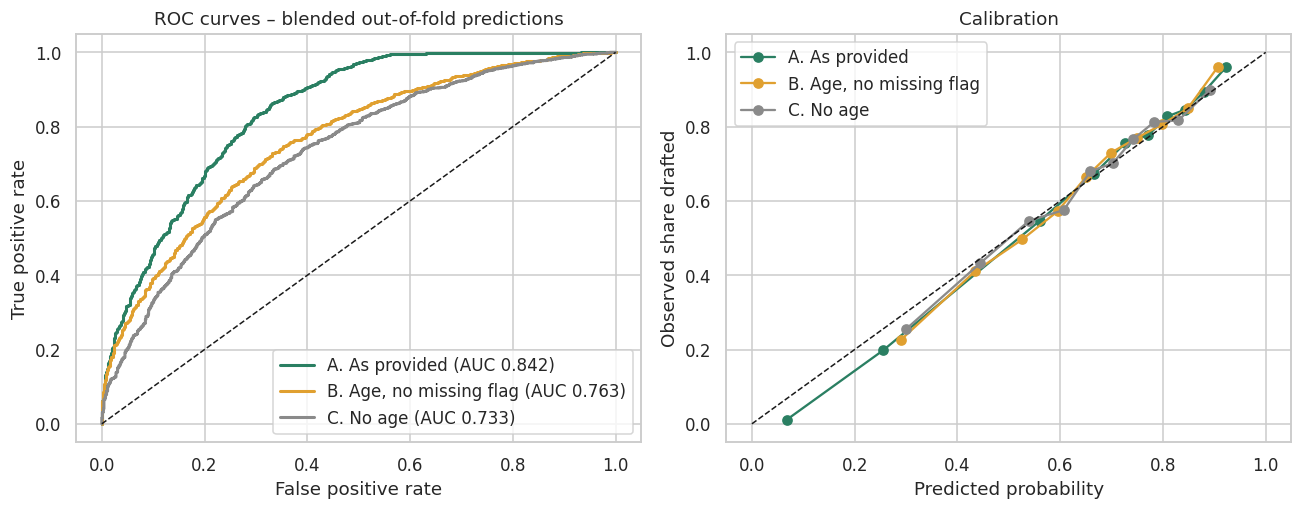

,AUC,Log loss,Brier score
A. As provided,0.8416,0.4318,0.1378
"B. Age, no missing flag",0.7634,0.5448,0.1836
C. No age,0.7326,0.5671,0.1923


In [14]:
blend = "Blend (equal weights)"
oof_mean = {s: oof[s][blend].mean(axis=0) for s in SCENARIOS}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for scen, col in zip(SCENARIOS, ["#2a7f62", "#e0a030", "#8a8a8a"]):
    fpr, tpr, _ = roc_curve(y, oof_mean[scen])
    ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{scen} (AUC {roc_auc_score(y, oof_mean[scen]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves – blended out-of-fold predictions"); ax[0].legend(loc="lower right")

for scen, col in zip(SCENARIOS, ["#2a7f62", "#e0a030", "#8a8a8a"]):
    frac, mean_p = calibration_curve(y, oof_mean[scen], n_bins=10, strategy="quantile")
    ax[1].plot(mean_p, frac, marker="o", color=col, label=scen)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("Predicted probability"); ax[1].set_ylabel("Observed share drafted")
ax[1].set_title("Calibration"); ax[1].legend(loc="upper left")
plt.tight_layout(); save("07_roc_and_calibration"); plt.show()

pd.DataFrame({
    "AUC": {s: roc_auc_score(y, oof_mean[s]) for s in SCENARIOS},
    "Log loss": {s: log_loss(y, oof_mean[s]) for s in SCENARIOS},
    "Brier score": {s: brier_score_loss(y, oof_mean[s]) for s in SCENARIOS},
}).round(4)

The curves sit close to the diagonal in all three scenarios, with slight over-prediction at the lowest probabilities (a handful of players predicted at ~25–30% are drafted ~20–25% of the time), so the probabilities can be read as rough draft likelihoods and not just rankings. Next: where does the more honest scenario B work well, and where does it struggle?

In [15]:
scenB = "B. Age, no missing flag"
pB = oof_mean[scenB]
rows = []
for grp, sub in train.assign(p=pB).groupby("Position_Type"):
    if sub.Drafted.nunique() == 2:
        rows.append({"Position_Type": grp, "n": len(sub), "draft_rate": sub.Drafted.mean(),
                     "AUC (within group)": roc_auc_score(sub.Drafted, sub.p)})
pd.DataFrame(rows).set_index("Position_Type").sort_values("AUC (within group)", ascending=False).round(3)

,n,draft_rate,AUC (within group)
Position_Type,,,
defensive_back,541,0.675,0.786
defensive_lineman,391,0.708,0.747
backs_receivers,1010,0.616,0.744
line_backer,309,0.728,0.735
offensive_lineman,435,0.664,0.733
kicking_specialist,82,0.256,0.707
other_special,13,0.308,0.500


Within-group AUC shows how well the model separates drafted from undrafted players *among players of the same position type*, a stricter test than the overall AUC, which also gets credit for knowing that kickers are rarely drafted. Performance is meaningfully above 0.5 for most groups, but the signal is weakest where the sample is small.

## 7. Feature importance

Gain-based importance from a LightGBM model trained on all labelled data, for the as-provided (A) and flag-free (B) scenarios.

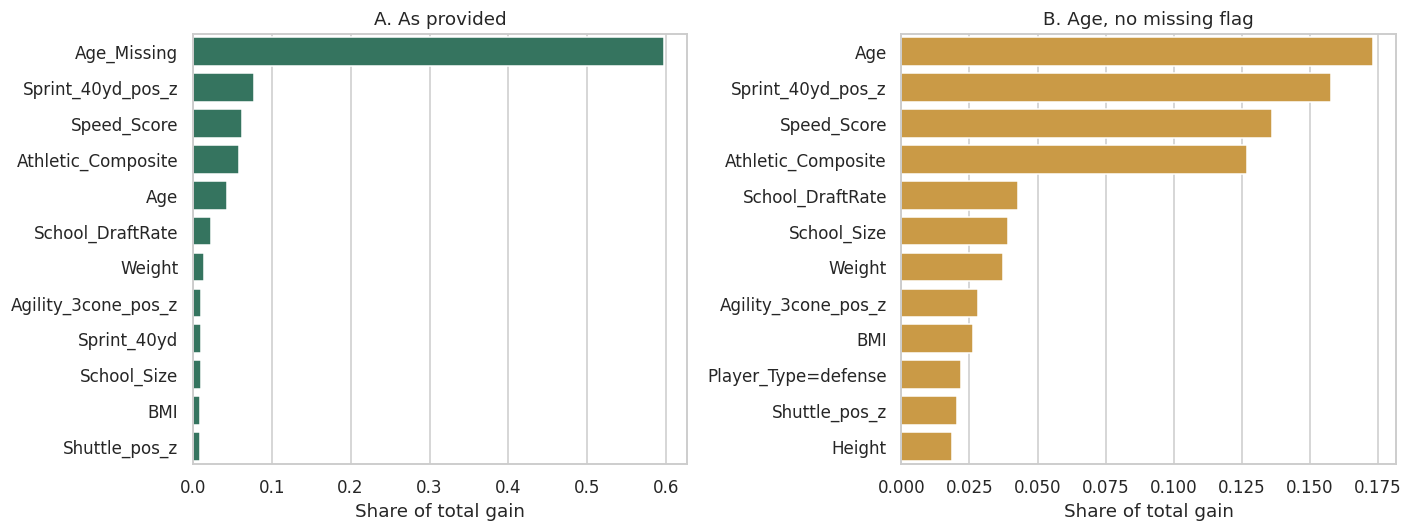

In [16]:
def lgbm_importance(fb_kwargs, top=12):
    fb = FeatureBuilder(**fb_kwargs)
    F = fb.fit_transform(X, y)
    m = make_models()["LightGBM"].set_params(importance_type="gain").fit(F, y)
    imp = pd.Series(m.feature_importances_, index=F.columns)
    return (imp / imp.sum()).sort_values(ascending=False).head(top)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (scen, kw) in zip(ax, list(SCENARIOS.items())[:2]):
    imp = lgbm_importance(kw)
    sns.barplot(x=imp.values, y=imp.index, ax=a, color="#2a7f62" if scen.startswith("A") else "#e0a030")
    a.set_title(scen); a.set_xlabel("Share of total gain"); a.set_ylabel("")
plt.tight_layout(); save("08_feature_importance"); plt.show()

In scenario A, `Age_Missing` alone accounts for about 60% of the total gain, consistent with section 3.4. Once it is removed (B), importance spreads across `Age` and speed-related features (`Sprint_40yd_pos_z`, `Speed_Score`) and `Athletic_Composite`, followed by the school's historical draft rate and size, a more football-like picture. Gain importance measures how often and how effectively a feature is used for splits, not whether it is irreplaceable: several of these features are correlated, which is why the ablation in section 5.1 shows small drops when any one group is removed.

## 8. Final predictions

The final models are fitted on **all** labelled players and used to score the unlabelled players in `test.csv`. Two prediction columns are saved so that the artifact-aware and artifact-free views are both available:

* `Drafted_Probability`: scenario A (uses everything in the data as provided)
* `Drafted_Probability_No_Age_Flag`: scenario B (does not use the missing-age indicator)

Both are equal-weight averages of the five model families.

In [17]:
def fit_predict(fb_kwargs):
    fb = FeatureBuilder(**fb_kwargs)
    Ftr, Fte = fb.fit_transform(X, y), fb.transform(test)
    assert list(Ftr.columns) == list(Fte.columns)
    preds = []
    for model in make_models().values():
        model.fit(Ftr, y)
        preds.append(model.predict_proba(Fte)[:, 1])
    return np.mean(preds, axis=0)

predictions = pd.DataFrame({
    "Id": test["Id"],
    "Drafted_Probability": fit_predict(SCENARIOS["A. As provided"]),
    "Drafted_Probability_No_Age_Flag": fit_predict(SCENARIOS["B. Age, no missing flag"]),
})
predictions.to_csv(OUT / "predictions.csv", index=False)

# sanity checks
assert len(predictions) == len(test) and predictions.Id.is_unique
assert predictions.iloc[:, 1:].apply(lambda s: s.between(0, 1).all()).all()
print(f"saved {len(predictions)} predictions to outputs/predictions.csv")
print("mean predicted draft rate:", predictions.iloc[:, 1:].mean().round(3).to_dict(), "| training rate:", round(y.mean(), 3))
print("correlation between the two columns:", round(predictions.iloc[:, 1:].corr().iloc[0, 1], 3))
predictions.describe().round(3)

saved 696 predictions to outputs/predictions.csv
mean predicted draft rate: {'Drafted_Probability': 0.632, 'Drafted_Probability_No_Age_Flag': 0.633} | training rate: 0.648
correlation between the two columns: 0.696


,Id,Drafted_Probability,Drafted_Probability_No_Age_Flag
count,696.000,696.000,696.000
mean,3128.500,0.632,0.633
std,201.062,0.276,0.188
min,2781.000,0.033,0.173
25%,2954.750,0.529,0.489
50%,3128.500,0.727,0.655
75%,3302.250,0.834,0.787
max,3476.000,0.967,0.961


## 9. Conclusions

**Results**

* On the data as provided, an equal-weight ensemble reaches **~0.84 cross-validated AUC**.
* Excluding the missing-age indicator, which acts as a proxy for the label, performance is **~0.76 AUC**, and this is the more trustworthy estimate of how well physical profile, age and position predict a draft selection.
* The signal is dominated by age information and position. With the age flag available, five very different learners land within ~0.004 AUC of each other; when the age value is kept but the flag removed (B), boosted trees are about 0.03 better than a linear model. Engineered features contribute small gains (≤0.005 AUC per group).

**Limitations**

* The label depends on things the data cannot see: college production, injuries, team needs and draft-day decisions. A ceiling well below perfect accuracy is expected.
* `Age` and some combine fields are missing in a way that is correlated with the outcome. Better data-collection documentation would be needed to separate genuine signal from artifact with certainty.
* Evaluation is a random split. Players from the same school and year appear in both folds, so a time-based split would be a stricter test of how well the model generalises to future classes.
* Dataset size (2,781 labelled players) limits how much hyper-parameter tuning is worthwhile.

**Possible next steps**

* Time-based validation (train on earlier years, test on later ones).
* Position-specific models or hierarchical modelling for the large position groups.
* Probability calibration (isotonic / Platt) on the final blend.
* Model explanation with SHAP values for individual players.